In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt, pandas as pd
torch.manual_seed(0); np.random.seed(0)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 1. Dane z opóźnionym znacznikiem
Każda sekwencja ma dwa kanały: losowe wartości i znaczniki. Losuję dwa różne znaczniki. Każdy wskazuje wartość sprzed 8 kroków. Celem modelu jest suma tych dwóch wartości.

In [2]:
def gen(N, L):
    X = np.zeros((N, L, 2), dtype=np.float32)
    X[:, :, 0] = np.random.rand(N, L)
    Y = np.zeros((N, 1), dtype=np.float32)

    for i in range(N):
        p = np.random.choice(np.arange(8, L), 2, replace=False)
        X[i, p, 1] = 1
        Y[i, 0] = X[i, p - 8, 0].sum()

    return torch.from_numpy(X).to(DEVICE), torch.from_numpy(Y).to(DEVICE)


def pokaz_przyklad(x, y):
    p = torch.where(x[:, 1] == 1)[0]
    a, b = x[p - 8, 0].tolist()

    for t in p.tolist():
        print(f"Znacznik w kroku {t + 1} → wartość z kroku {t - 8 + 1}")

    print(f"Suma z odczytanych wartości: {a:.6f} + {b:.6f} ≈ {a + b:.6f}")
    print(f"Cel z generatora: {y.item():.6f}")
    assert np.isclose(a + b, y.item())


np.random.seed(0)
X, Y = gen(1, 20)
pokaz_przyklad(X[0], Y[0])

Znacznik w kroku 13 → wartość z kroku 5
Znacznik w kroku 18 → wartość z kroku 10
Suma z odczytanych wartości: 0.423655 + 0.383442 ≈ 0.807096
Cel z generatora: 0.807096


In [3]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        warstwa = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[typ]
        self.rnn = warstwa(2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

## 2. Modele i ustawienia
Modele rekurencyjne korzystają z ostatniego stanu ukrytego, a Conv1D uśrednia cechy po czasie. W porównaniu podstawowym używam stanu ukrytego 32 i 32 kanałów w Conv1D. Wszystkie modele mają po 30 epok, batch 128, Adam z lr=0.005 i obcinanie normy gradientu do 1.0.

In [4]:
class ConvNet(nn.Module):
    def __init__(self, d=(1, 2, 4)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(2, 32, 3, padding=d[0], dilation=d[0]),
            nn.ReLU(),
            nn.Conv1d(32, 32, 3, padding=d[1], dilation=d[1]),
            nn.ReLU(),
            nn.Conv1d(32, 32, 3, padding=d[2], dilation=d[2]),
            nn.ReLU(),
        )
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2))
        return self.fc(h.mean(dim=2))


def trenuj(model, trening, test):
    Xtr, Ytr = trening
    Xte, Yte = test
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=0.005)
    loss = nn.MSELoss()

    torch.manual_seed(0)
    model.train()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    for _ in range(30):
        for idx in torch.randperm(len(Xtr), device=DEVICE).split(128):
            opt.zero_grad()
            loss(model(Xtr[idx]), Ytr[idx]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    czas = time.perf_counter() - start

    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(x) for x in Xte.split(128)])
        mse = loss(pred, Yte).item()

    return mse, czas, pred

## 3. Porównanie czterech modeli
Hipoteza. Przy dłuższej sekwencji SimpleRNN będzie miał większy problem z zachowaniem informacji do ostatniego kroku. Sprawdzam, czy LSTM i GRU lepiej poradzą sobie z wydłużeniem wejścia. Dla każdego L używam tych samych 4000 przykładów treningowych i 800 testowych we wszystkich modelach. Punktem odniesienia jest stała predykcja równa średniej celu z treningu.

In [5]:
np.random.seed(0)
dane = {L: (gen(4000, L), gen(800, L)) for L in (50, 100)}
predykcje = {}

print("Urządzenie:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("Ziarno losowania:", 0)


def ocen(L, nazwa, utworz_model):
    torch.manual_seed(0)
    model = utworz_model()
    mse, czas, pred = trenuj(model, *dane[L])
    predykcje[L, nazwa] = pred

    return {
        "L": L,
        "Model": nazwa,
        "Test MSE": mse,
        "Czas [s]": czas,
        "Parametry": sum(p.numel() for p in model.parameters()),
    }


modele = {
    "SimpleRNN": lambda: RNNNet("RNN", hidden=32),
    "LSTM": lambda: RNNNet("LSTM", hidden=32),
    "GRU": lambda: RNNNet("GRU", hidden=32),
    "Conv1D": ConvNet,
}

wiersze = []
for L, (trening, test) in dane.items():
    mse_stalej = ((test[1] - trening[1].mean()) ** 2).mean().item()
    wiersze.append({"L": L, "Model": "Średnia treningu", "Test MSE": mse_stalej})

    for nazwa, utworz_model in modele.items():
        wiersze.append(ocen(L, nazwa, utworz_model))

glowne = pd.DataFrame(wiersze).astype({"Parametry": "Int64"})
display(glowne.style.format({"Test MSE": "{:.5f}", "Czas [s]": "{:.2f}"}, na_rep="—"))

Urządzenie: CPU
Ziarno losowania: 0


,L,Model,Test MSE,Czas [s],Parametry
0,50,Średnia treningu,0.16064,—,—
1,50,SimpleRNN,0.16166,2.40,1185
2,50,LSTM,0.16095,6.60,4641
3,50,GRU,0.14852,5.50,3489
4,50,Conv1D,0.15364,16.34,6465
5,100,Średnia treningu,0.16734,—,—
6,100,SimpleRNN,0.16916,4.51,1185
7,100,LSTM,0.16934,13.40,4641
8,100,GRU,0.16647,11.37,3489
9,100,Conv1D,0.17110,21.64,6465


## 4. Dwa dodatkowe treningi dla L = 100
Zwiększam stan ukryty SimpleRNN z 32 do 64 i sprawdzam, jak zmieniają się błąd, czas i liczba parametrów. W Conv1D zmieniam tylko dylatacje. Przy jądrze 3, kroku 1 i symetrycznym dopełnieniu padding=d długość sekwencji jest zachowana. Pole recepcyjne wynosi \(1+2\sum d\), czyli 15 dla [1, 2, 4] i 7 dla [1, 1, 1]. Przy odległości 8 kroków jedna pozycja mapy cech może objąć znacznik i wskazywaną wartość w wariancie z polem 15.

In [6]:
dodatkowe = pd.DataFrame([
    ocen(100, "SimpleRNN h=64", lambda: RNNNet("RNN", hidden=64)),
    ocen(100, "Conv1D [1,1,1]", lambda: ConvNet(d=(1, 1, 1))),
])

podstawowe = glowne[
    (glowne["L"] == 100) & glowne["Model"].isin(["SimpleRNN", "Conv1D"])
]

pd.concat([podstawowe, dodatkowe], ignore_index=True).round({
    "Test MSE": 5,
    "Czas [s]": 2,
})

,L,Model,Test MSE,Czas [s],Parametry
0,100,SimpleRNN,0.16916,4.51,1185
1,100,Conv1D,0.17110,21.64,6465
2,100,SimpleRNN h=64,0.16881,5.68,4417
3,100,"Conv1D [1,1,1]",0.17134,18.65,6465


## 5. Wykres i przykład z dużym błędem
Pierwsza komórka pokazuje wpływ długości. Przerywana linia to MSE predykcji stałej obliczone osobno dla każdego L.

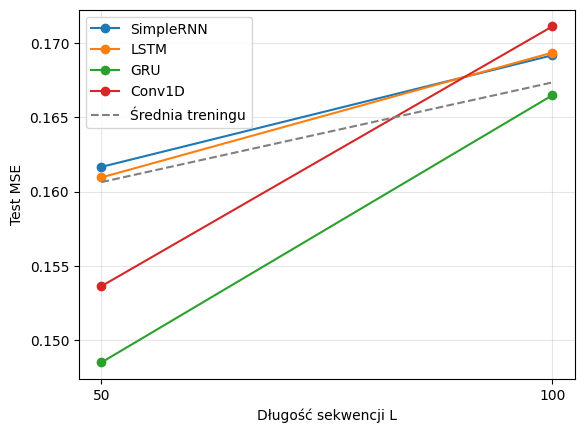

In [7]:
mse = glowne.pivot(index="L", columns="Model", values="Test MSE")

for nazwa in modele:
    plt.plot(mse.index, mse[nazwa], "o-", label=nazwa)

plt.plot(mse.index, mse["Średnia treningu"], "--", color="gray",
         label="Średnia treningu")
plt.xticks([50, 100])
plt.xlabel("Długość sekwencji L")
plt.ylabel("Test MSE")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("wykres_lab4.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
Xte, Yte = dane[100][1]
pred = predykcje[100, "SimpleRNN"]
blad = (pred - Yte).square()
i = blad.argmax().item()

pokaz_przyklad(Xte[i], Yte[i])
print(f"Predykcja SimpleRNN: {pred[i].item():.6f}")
print(f"Błąd kwadratowy: {blad[i].item():.6f}")

ostatni = torch.where(Xte[i, :, 1] == 1)[0][-1].item() + 1
print("Kroki od ostatniego znacznika do odczytu:", 100 - ostatni)

Znacznik w kroku 21 → wartość z kroku 13
Znacznik w kroku 99 → wartość z kroku 91
Suma z odczytanych wartości: 0.036054 + 0.010872 ≈ 0.046926
Cel z generatora: 0.046926
Predykcja SimpleRNN: 1.102305
Błąd kwadratowy: 1.113825
Kroki od ostatniego znacznika do odczytu: 1
